## Ćwiczenie 7: Algorytm Otsu

Metoda Otsu (1979) to fundament automatycznej segmentacji. Zamiast ręcznie zgadywać, gdzie znajduje się granica jasności między zdrową tkanką a tłem (lub kością), algorytm szuka jej matematycznie, opierając się na analizie histogramu.

### Idea algorytmu: minimalizacja wariancji
Otsu dzieli piksele na dwie klasy (Tło i Obiekt) sprawdzając każdy możliwy próg $T$. Wybiera ten próg, dla którego piksele wewnątrz obu grup są do siebie maksymalnie podobne, a różnica między dwiema grupami jest maksymalnie duża (maksymalizacja wariancji międzyklasowej).

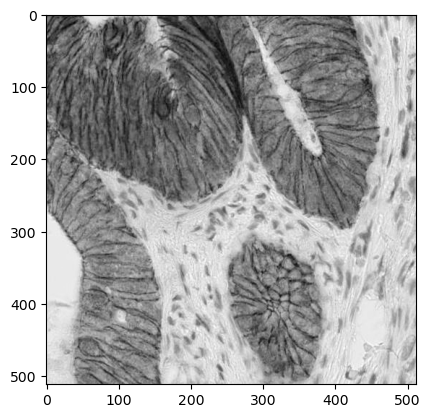

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, color

# 1. Przygotowanie obrazu (użyjemy immunochemii z wbudowanych danych, świetny dwumodalny przykład)
image = color.rgb2gray(data.immunohistochemistry()) * 255
image = image.astype(np.uint8)

# 2. Zbudowanie histogramu
counts, bin_edges = np.histogram(image.ravel(), bins=256, range=(0, 255))
bin_centers = bin_edges[:-1]  # Odrzucamy ostatnią krawędź, wyrównując rozmiar do 256

# 3. Symulacja ręcznego wyliczania wariancji międzyklasowej dla każdego progu T
variances = []
total_pixels = image.size

for t in range(256):
    # Podział na klasę 0 (Tło) i klasę 1 (Obiekt)
    w0 = np.sum(counts[:t]) / total_pixels
    w1 = np.sum(counts[t:]) / total_pixels
    
    # Zabezpieczenie przed dzieleniem przez zero
    if w0 == 0 or w1 == 0:
        variances.append(0)
        continue
        
    # Średnie jasności w klasach
    mu0 = np.sum(counts[:t] * np.arange(t)) / np.sum(counts[:t])
    mu1 = np.sum(counts[t:] * np.arange(t, 256)) / np.sum(counts[t:])
    
    # Wariancja międzyklasowa (Between-class variance)
    var_between = w0 * w1 * (mu0 - mu1)**2
    variances.append(var_between)

variances = np.array(variances)
optimal_t = np.argmax(variances)

# Weryfikacja z gotową funkcją skimage
skimage_otsu = filters.threshold_otsu(image)

plt.imshow(image, cmap='gray')

### Wizualizacja poszukiwania optymalnego progu

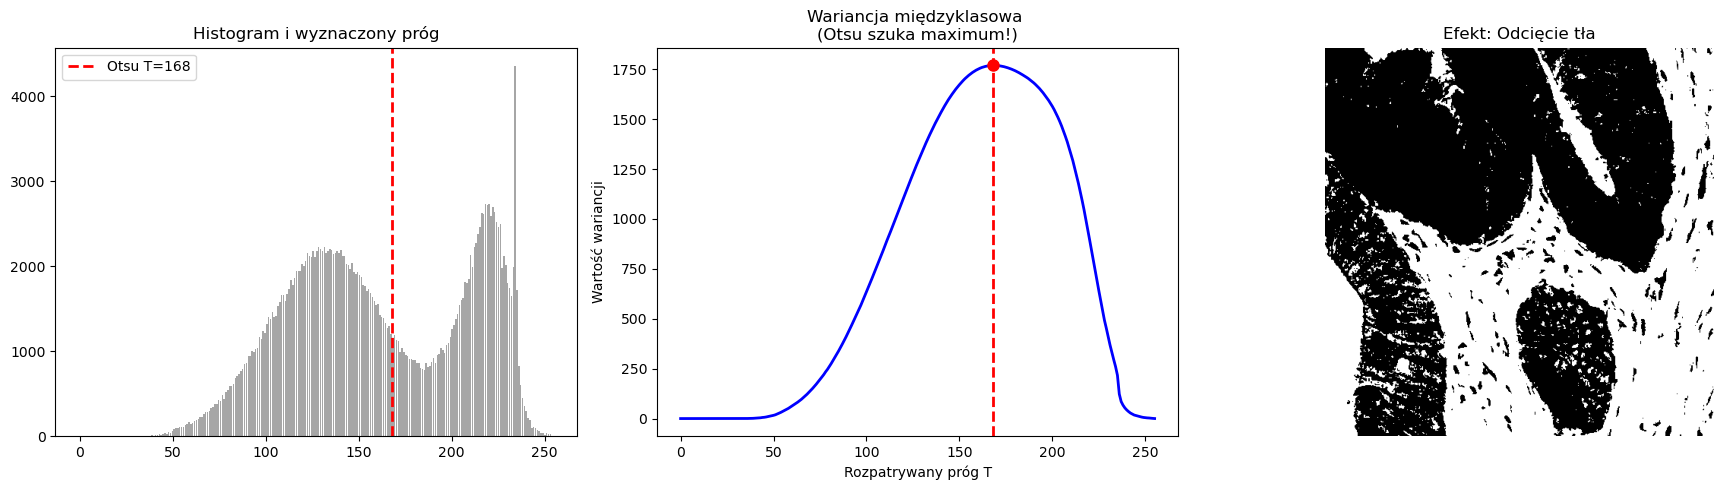

Nasz ręcznie wyliczony próg Otsu: 168
Próg wyliczony przez scikit-image: 167
Są identyczne, co dowodzi, że funkcja maksymalizowana przez Otsu działa dokładnie tak, jak to opisaliśmy.


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Histogram
axes[0].bar(bin_centers, counts, color='gray', alpha=0.7)
axes[0].axvline(optimal_t, color='red', linestyle='--', lw=2, label=f'Otsu T={optimal_t}')
axes[0].set_title('Histogram i wyznaczony próg')
axes[0].legend()

# Panel 2: Funkcja wariancji międzyklasowej
axes[1].plot(range(256), variances, color='blue', lw=2)
axes[1].axvline(optimal_t, color='red', linestyle='--', lw=2)
axes[1].plot(optimal_t, variances[optimal_t], 'ro', markersize=8)
axes[1].set_title('Wariancja międzyklasowa \n(Otsu szuka maximum!)')
axes[1].set_xlabel('Rozpatrywany próg T')
axes[1].set_ylabel('Wartość wariancji')

# Panel 3: Wynik binaryzacji
binary = image > optimal_t
axes[2].imshow(binary, cmap='gray')
axes[2].set_title('Efekt: Odcięcie tła')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"Nasz ręcznie wyliczony próg Otsu: {optimal_t}")
print(f"Próg wyliczony przez scikit-image: {skimage_otsu}")
print("Są identyczne, co dowodzi, że funkcja maksymalizowana przez Otsu działa dokładnie tak, jak to opisaliśmy.")